# 04 参数初始化、网络训练与损失函数


本篇对应 **day04**，是「06-深度学习神经网络」7篇笔记中的第4篇。承接03的线性回归、网络结构和激活函数，继续学习参数初始化、网络搭建与训练、多分类与二分类交叉熵、MAE、MSE、Smooth L1，以及梯度下降和反向传播。

资料：[深度学习神经网络课程资料](https://pan.baidu.com/s/1FPhKS2qMBgnqVOXCyhBTog?pwd=1234)，提取码 `1234`。已核对 `04_深度学习神经网络/视频/day04` 的 **13个视频文件标题**。教师 `课堂笔记.zip` 和 `课件.zip` 正文未取得，视频未逐段转录；本文按目录组织主题，说明、人工数据、代码和图均为独立编写，不能视为教师原文或课堂案例的复刻。

全部为Markdown单元，Python代码按顺序复制到代码单元即可练习。图片直接存储为当前Notebook的附件，阅读不依赖其他图片文件。


## 本篇学习路线

| 对应视频 | 学习内容 | 需要掌握 |
| --- | --- | --- |
| 01—02 | 参数初始化 | 打破隐藏单元对称性，按层与激活选择尺度 |
| 03—06 | 网络搭建与模型训练 | Module、forward、数据批次、损失、反向和参数更新 |
| 07—08 | 多分类/二分类交叉熵 | 区分logits与概率，匹配标签形状和类型 |
| 09—11 | MAE、MSE、Smooth L1 | 区分对残差的惩罚与梯度 |
| 12—13 | 梯度下降与反向传播 | 理解更新方向与链式法则 |

本篇训练一个 **2→12→3** 的小型三分类网络，使用人工生成的二维样本。它用于把步骤连起来，不代表课程中的原始数据和网络。SGD只作为本篇的更新工具，优化器比较、学习率策略、Dropout和BatchNorm在05继续展开。


## 1. 环境与运行约定

使用 `torch`，本篇全部例子在CPU运行，不需要下载训练数据。图已经内嵌，阅读时无需安装绘图库。

```bash
python -m pip install torch
```

```python
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(2026)
print("PyTorch:", torch.__version__)
```

代码按顺序执行。固定种子便于同环境复现，但版本、设备与算法也会影响随机结果，不能保证跨平台逐位一致。


## 2. 为什么需要初始化

参数初始化决定模型第一次前向使用的权重与偏置。合适的初始化主要解决两件事：

- **隐藏单元不能完全一样**：如果同层隐藏单元的权重、偏置完全相同，且计算和更新规则也相同，它们通常会得到相同输出与梯度，难以学到不同特征。
- **数值尺度要合适**：权重过大可能让Sigmoid/Tanh进入饱和区；多层传播中过大或过小的方差也可能让信号与梯度失衡。

零初始化不是对所有参数都错误。许多网络的偏置可以初始化为0；上一篇只有斜率和截距的线性回归也能从0开始。需要避免的是让一般多层网络的隐藏权重完全对称，不能把“偏置为0”与“所有隐藏权重为0”混为一谈。

```python
same_hidden = nn.Linear(2, 3)
same_output = nn.Linear(3, 1)
with torch.no_grad():
    same_hidden.weight.fill_(0.2)
    same_hidden.bias.zero_()
    same_output.weight.fill_(0.5)
    same_output.bias.zero_()

symmetry_x = torch.tensor([[1.0, 2.0], [-1.0, 0.0]])
symmetry_target = torch.tensor([[1.0], [0.0]])
hidden_values = torch.tanh(same_hidden(symmetry_x))
symmetry_loss = F.mse_loss(same_output(hidden_values), symmetry_target)
symmetry_loss.backward()
assert torch.allclose(hidden_values[:, 0], hidden_values[:, 1])
assert torch.allclose(same_hidden.weight.grad[0], same_hidden.weight.grad[1])
assert torch.allclose(same_hidden.weight.grad[1], same_hidden.weight.grad[2])
print("相同隐藏单元产生相同输出与梯度")
```

本例显式让输出连接也对称，说明这种对称如何保留下来；不能由此断言任意初始化或网络结构都具有同样结果。


## 3. nn.init常用接口：就地修改参数

`nn.init` 中结尾带 `_` 的接口通常原地修改张量，并在初始化时避免记录普通的求导图。初始化后参数仍应能训练。

| 方法 | 含义 | 用途 |
| --- | --- | --- |
| `zeros_`、`ones_`、`constant_` | 全0、全1、指定常量 | 演示、偏置或特定结构 |
| `uniform_(a,b)` | 均匀分布 | 明确指定区间的随机权重 |
| `normal_(mean,std)` | 正态分布 | 明确指定均值与尺度 |
| `xavier_uniform_ / normal_` | Xavier/Glorot初始化 | 按输入与输出规模控制方差 |
| `kaiming_uniform_ / normal_` | Kaiming/He初始化 | 常用于ReLU/LeakyReLU网络 |

```python
initialization_generator = torch.Generator().manual_seed(2026)
example_parameter = nn.Parameter(torch.empty(4, 3))
nn.init.uniform_(example_parameter, a=-0.2, b=0.2,
                 generator=initialization_generator)
assert example_parameter.requires_grad and example_parameter.is_leaf
assert torch.all(example_parameter >= -0.2)
assert torch.all(example_parameter <= 0.2)

example_bias = nn.Parameter(torch.empty(4))
nn.init.zeros_(example_bias)
assert torch.equal(example_bias, torch.zeros(4))
print(example_parameter)
```

给已有参数赋初值时不要随意把 `nn.Parameter` 替换成普通Tensor，否则可能失去参数注册。也不要在训练中每个batch都重新初始化；初始化通常在创建模型后、开始训练前完成。


## 4. fan_in、fan_out与Xavier

对 `nn.Linear(in_features,out_features)`，权重存储形状是 `(out_features,in_features)`：

- `fan_in` 为每个输出单元接收的输入数量。
- `fan_out` 为输入连接到的输出数量。

Xavier均匀分布常用范围：

$$W\sim U(-a,a),\quad a=g\sqrt{\frac{6}{fan\_in+fan\_out}}.$$

Xavier正态分布的标准差：

$$\sigma=g\sqrt{\frac{2}{fan\_in+fan\_out}}.$$

g是gain，用于配合激活函数。`nn.init.calculate_gain("tanh")` 的常用值为5/3；它是初始化策略的一部分，不保证每个网络都最佳。

```python
fan_in, fan_out = 3, 4
xavier_gain = nn.init.calculate_gain("tanh")
xavier_weight = torch.empty(fan_out, fan_in)
nn.init.xavier_uniform_(xavier_weight, gain=xavier_gain,
                        generator=torch.Generator().manual_seed(11))
xavier_bound = xavier_gain * (6 / (fan_in + fan_out)) ** 0.5
assert torch.all(xavier_weight.abs() <= xavier_bound)
assert abs(xavier_gain - 5 / 3) < 1e-12
print("shape:", xavier_weight.shape, "均匀分布边界:", xavier_bound)
```

API按权重的布局计算fan。如果自定义矩阵采用 `X@W`、W形状为 `(in,out)`，初始化时需要结合实际布局处理，例如按转置视图初始化，不能照搬Linear权重的方向。


## 5. Kaiming：配合ReLU控制方差

对ReLU，常见Kaiming正态初始化使用 `mode="fan_in"`：

$$\sigma=\sqrt{\frac{2}{fan\_in}}.$$

`fan_in` 模式重点保持前向信号的方差尺度；`fan_out` 模式重点考虑反向梯度传播。LeakyReLU要传入相应负斜率a，不能一律使用ReLU的设置。

```python
hidden_weight = torch.empty(12, 2)
nn.init.kaiming_normal_(hidden_weight, mode="fan_in",
                        nonlinearity="relu",
                        generator=torch.Generator().manual_seed(12))
hidden_uniform = torch.empty(12, 2)
nn.init.kaiming_uniform_(hidden_uniform, mode="fan_in",
                         nonlinearity="relu",
                         generator=torch.Generator().manual_seed(12))
kaiming_bound = (6 / 2) ** 0.5
assert torch.all(hidden_uniform.abs() <= kaiming_bound)
print("ReLU正态分布理论标准差:", (2 / 2) ** 0.5)
```

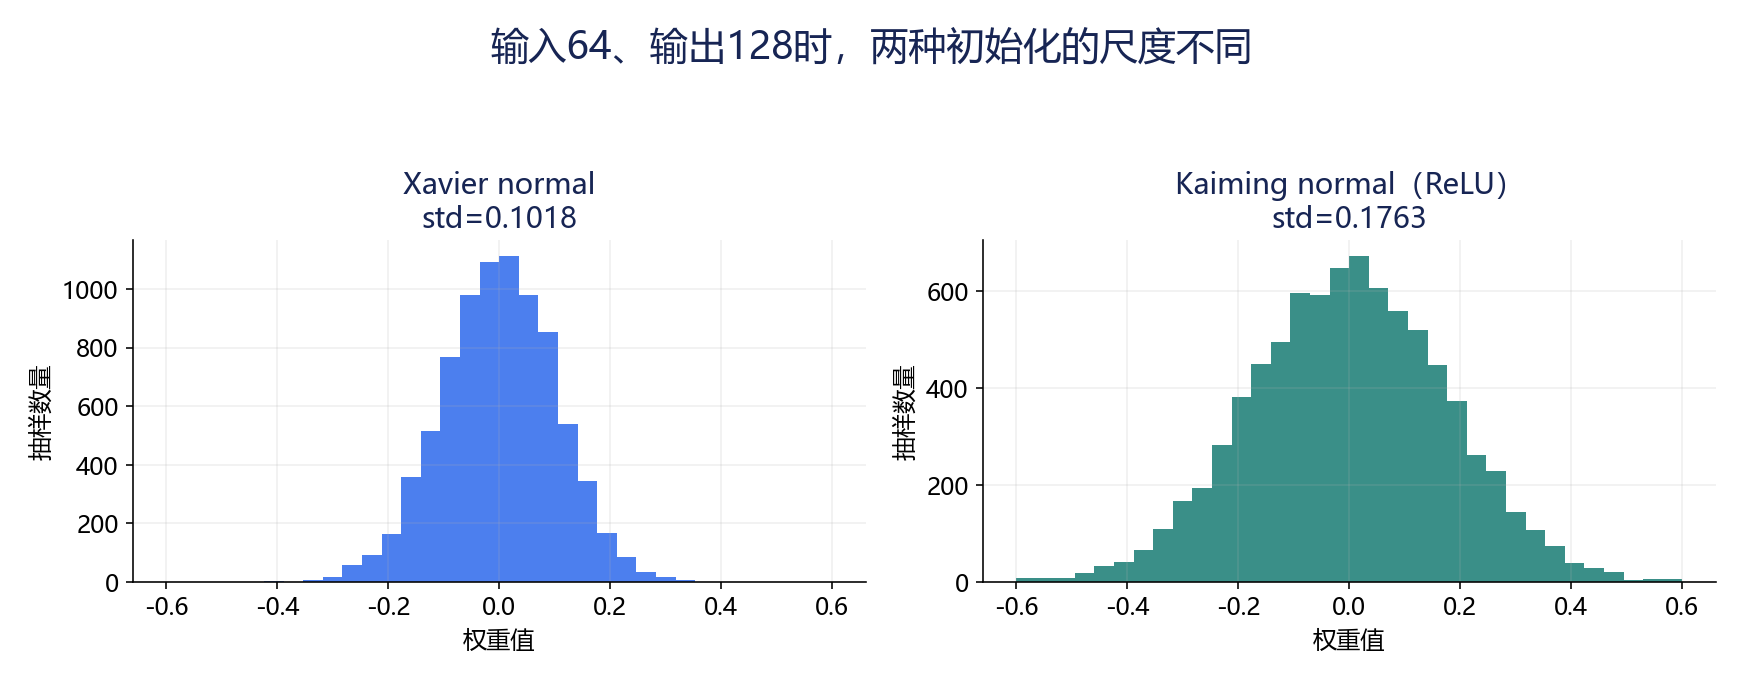

图中用输入数64、输出数128的权重比较Xavier(gain=1)与Kaiming(ReLU,fan_in)正态抽样；随机样本标准差不必恰好等于理论值。没有一种初始化能替代输入处理、合适的学习率与训练检查。

`nn.Linear` 自身已有默认初始化，不能说“不手动初始化就是所有权重为0”。手动初始化是根据网络设计显式选择策略；不要把框架默认行为直接称为标准ReLU He初始化。


## 6. 搭建网络：定义结构，再定义forward

自定义网络通常继承 `nn.Module`。在 `__init__` 中创建层、调用 `super().__init__()`；在 `forward` 中描述数据如何流动。

本例输入2个特征，隐藏层12个单元配ReLU，输出3个类别logits。最后一层不用Softmax，后面直接交给CrossEntropyLoss。

```python
class TinyClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(2, 12)
        self.output = nn.Linear(12, 3)
        self.reset_parameters_for_course()

    def reset_parameters_for_course(self):
        nn.init.kaiming_normal_(self.hidden.weight, mode="fan_in",
                                nonlinearity="relu")
        nn.init.zeros_(self.hidden.bias)
        nn.init.xavier_uniform_(self.output.weight, gain=1.0)
        nn.init.zeros_(self.output.bias)

    def forward(self, x):
        hidden = torch.relu(self.hidden(x))
        return self.output(hidden)

torch.manual_seed(2026)
model = TinyClassifier()
probe_logits = model(torch.zeros(5, 2))
assert probe_logits.shape == (5, 3)
assert sum(p.numel() for p in model.parameters()) == 75
print(model)
for name, parameter in model.named_parameters():
    print(name, tuple(parameter.shape))
```

参数数目：`2×12+12=36`，`12×3+3=39`，合计75。初始化策略是本独立示例的选择：隐藏ReLU层用Kaiming，线性输出层用Xavier(gain=1)。


### 6.1 参数注册与调用方式

将层作为Module的属性，会注册为子模块，参数能被 `model.parameters()` 找到。若需要动态层列表，使用 `nn.ModuleList`；普通Python列表不会自动注册内部层。

```python
class RegisteredLayers(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.ModuleList([nn.Linear(2, 4), nn.Linear(4, 3)])

registered = RegisteredLayers()
assert len(list(registered.parameters())) == 4
assert "layers.0.weight" in registered.state_dict()
print(list(registered.state_dict()))
```

本小例只演示注册，没有实现forward，不用于训练。正式调用通常用 `model(x)`，让Module的调用流程和hooks等机制生效。forward中不要每次重新创建Linear，那会反复新建参数而无法正常持续学习。

`nn.Sequential` 适合简单按顺序的网络；`nn.Module` 更便于表达分支、多输入或其他流程。


## 7. 人工数据与训练/测试划分

生成三团二维样本，类别中心分别为 `(-2,-1)、(2,-1)、(0,2)`，每类60个样本。每类随机取48个用于训练、12个用于测试，保证两个集合都包含三类。

```python
data_generator = torch.Generator().manual_seed(2026)
centers = torch.tensor([[-2.0, -1.0], [2.0, -1.0], [0.0, 2.0]])
grouped_features = centers[:, None, :] + 0.55 * torch.randn(
    3, 60, 2, generator=data_generator)
all_features = grouped_features.reshape(180, 2)
all_labels = torch.arange(3).repeat_interleave(60)

split_generator = torch.Generator().manual_seed(7)
train_parts, test_parts = [], []
for class_id in range(3):
    indices = torch.randperm(60, generator=split_generator) + class_id * 60
    train_parts.append(indices[:48])
    test_parts.append(indices[48:])
train_indices = torch.cat(train_parts)
test_indices = torch.cat(test_parts)
train_features, train_labels = all_features[train_indices], all_labels[train_indices]
test_features, test_labels = all_features[test_indices], all_labels[test_indices]

assert train_features.shape == (144, 2)
assert test_features.shape == (36, 2)
assert train_labels.dtype == torch.long
assert torch.equal(train_labels.bincount(minlength=3), torch.tensor([48, 48, 48]))
assert torch.equal(test_labels.bincount(minlength=3), torch.tensor([12, 12, 12]))
assert set(train_indices.tolist()).isdisjoint(test_indices.tolist())
```

输入采用float32，整数类别标签采用long，取值0、1、2。标签不是 `(N,3)` 的one-hot，本篇使用最常见的整数类别标签接口。这类人工数据较容易分类，测试表现不代表现实业务能力。


## 8. Dataset、DataLoader、batch与epoch

`TensorDataset` 将特征与标签配对；`DataLoader` 按批次取样，训练通常打乱顺序。

```python
train_dataset = TensorDataset(train_features, train_labels)
train_loader = DataLoader(
    train_dataset, batch_size=24, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(99),
)
assert len(train_loader) == 6
sample_features, sample_labels = next(iter(train_loader))
assert sample_features.shape == (24, 2)
assert sample_labels.shape == (24,)
print("每个epoch批次数:", len(train_loader))
```

一个batch包含24个样本，一个epoch遍历144个训练样本，因此本例每个epoch更新6次参数。`num_workers=0` 让数据加载在当前进程完成，便于Notebook和Windows中直接运行。

数据不足整批时，最后一批通常更小；默认 `drop_last=False`。本例144恰好被24整除，但统计平均损失时仍按样本数加权，便于迁移到其他规模的数据。


## 9. 训练流程：用loss连接所有可训练层

每个batch执行：

`zero_grad → forward → loss → backward → step`。

`loss.backward()` 把梯度写入参数；`optimizer.step()` 才会更新参数。`model.train()` 切换训练行为，不会自动启动训练；`model.eval()` 也不会自动关闭梯度。

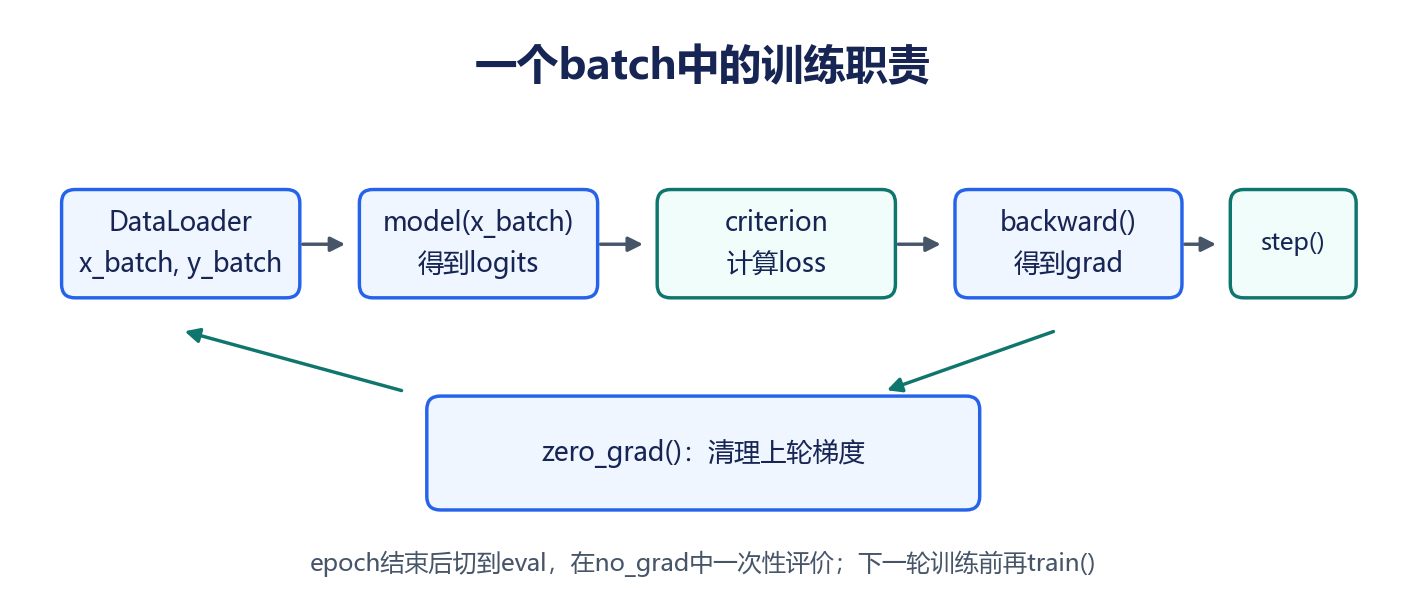

```python
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
assert sum(p.numel() for group in optimizer.param_groups for p in group["params"]) == 75

def evaluate_classifier(network, features, labels):
    network.eval()
    with torch.no_grad():
        logits = network(features)
        assert logits.shape == (len(labels), 3)
        mean_loss = criterion(logits, labels).item()
        accuracy = (logits.argmax(dim=1) == labels).float().mean().item()
    return mean_loss, accuracy

initial_train_loss, initial_train_accuracy = evaluate_classifier(
    model, train_features, train_labels)
print("初始训练损失:", initial_train_loss)
```

evaluate只计算当前结果，不更新参数。该函数调用eval后，训练循环会在下一轮显式调用train。本例没有Dropout或BatchNorm，但保留正确的模式切换，后续加入这些层时不必改训练思路。


## 10. 完整模型训练

预先设置80个epoch，共480次batch更新。训练过程中只观察训练集；测试集在训练结束后评价，不根据测试结果反复调参数。

```python
epochs = 80
training_log = []
for epoch in range(epochs):
    model.train()
    batch_loss_sum = 0.0
    seen_samples = 0
    for batch_features, batch_labels in train_loader:
        optimizer.zero_grad(set_to_none=True)
        batch_logits = model(batch_features)
        assert batch_logits.shape == (len(batch_labels), 3)
        batch_loss = criterion(batch_logits, batch_labels)
        batch_loss.backward()
        optimizer.step()

        batch_loss_sum += batch_loss.item() * len(batch_labels)
        seen_samples += len(batch_labels)

    epoch_train_loss, epoch_train_accuracy = evaluate_classifier(
        model, train_features, train_labels)
    training_log.append({
        "epoch": epoch + 1,
        "during_update_mean_loss": batch_loss_sum / seen_samples,
        "after_epoch_train_loss": epoch_train_loss,
        "after_epoch_train_accuracy": epoch_train_accuracy,
    })

final_train_loss, final_train_accuracy = evaluate_classifier(
    model, train_features, train_labels)
test_loss, test_accuracy = evaluate_classifier(model, test_features, test_labels)
print(f"训练loss: {initial_train_loss:.4f} -> {final_train_loss:.4f}")
print(f"训练准确率: {final_train_accuracy:.2%}")
print(f"测试loss={test_loss:.4f}, 测试准确率={test_accuracy:.2%}")
assert final_train_loss < initial_train_loss
assert final_train_accuracy > 0.95
assert test_accuracy > 0.9
```

`during_update_mean_loss` 是不同batch、不同参数状态下损失的加权均值；`after_epoch_train_loss` 是该epoch结束后，用同一模型状态对完整训练集计算的损失。它们不同，绘图使用后者，避免把两种统计混为一谈。

损失提供连续的优化信号；argmax准确率用于评价。不能拿argmax后的类别编号当作需要求导的训练目标。


## 11. 训练结果与推理

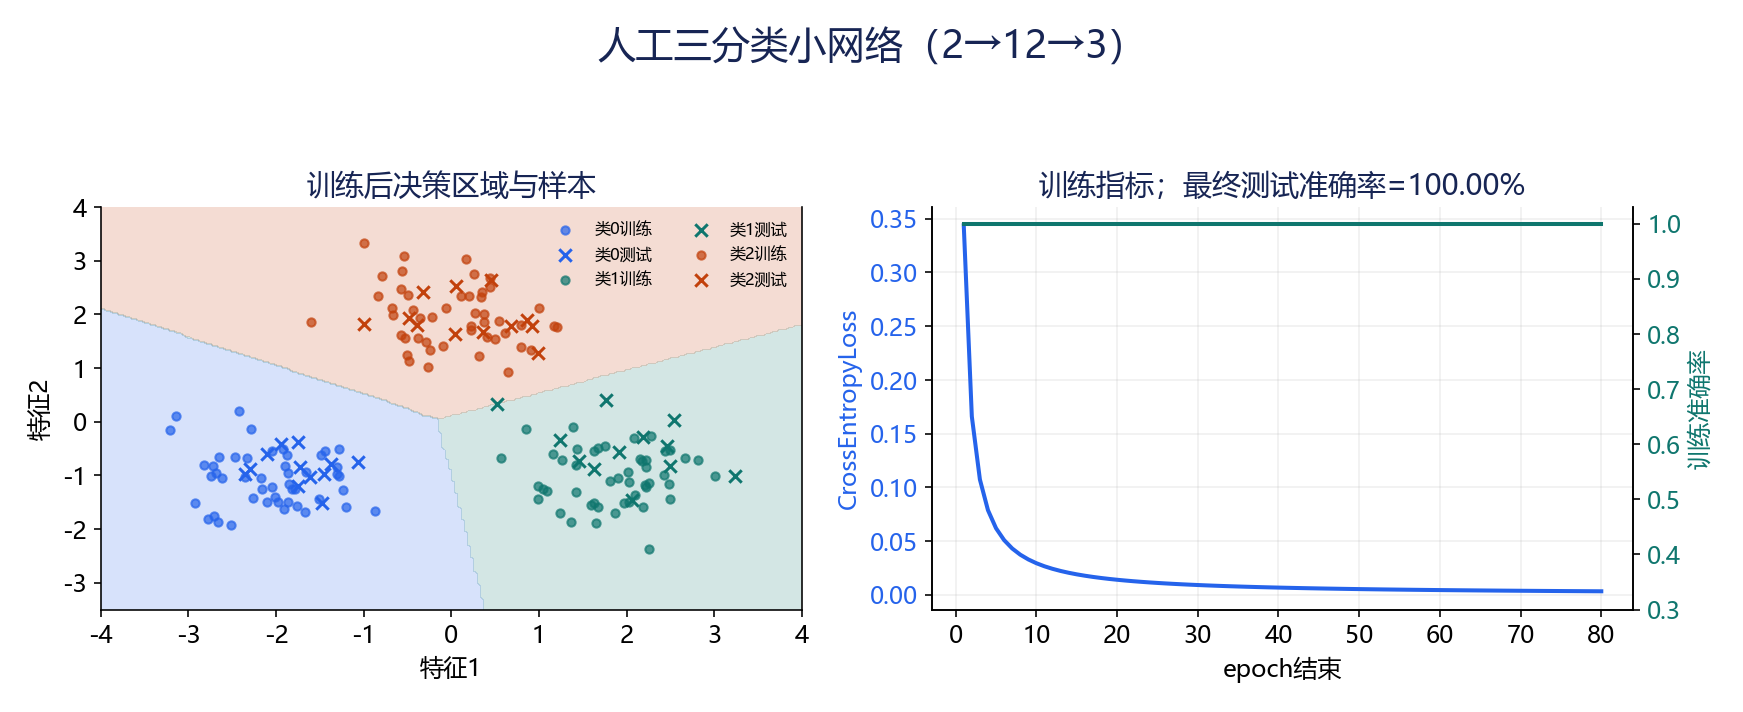

图左展示模型的决策区域，训练样本用圆点，测试样本用叉号；右侧记录每个epoch结束后的训练loss与准确率。全部数值来自本篇实际运行，不是另画的示意下降曲线。

```python
model.eval()
with torch.no_grad():
    query_features = centers.clone()
    query_logits = model(query_features)
    query_probabilities = torch.softmax(query_logits, dim=1)
    query_classes = query_logits.argmax(dim=1)
assert torch.allclose(query_probabilities.sum(dim=1), torch.ones(3), atol=1e-6)
assert torch.equal(query_classes, torch.tensor([0, 1, 2]))
print(query_classes)
print(query_probabilities)
```

选择最大类别时直接对logits做argmax即可，Softmax保持同一组分数的排序。只有需要查看概率形式时才显式Softmax。网络在未覆盖的区域仍会输出类别与分数，不能把决策图当成所有输入都可靠的证明。


## 12. 多分类交叉熵：惩罚正确类别的低概率

对单个样本，正确类别为y，模型Softmax概率为p：

$$L=-\log p_y.$$

正确类概率越高，损失越小。模型把错误类别分数抬高时，会间接压低正确类概率，因此交叉熵同时关注类别竞争。

对常见整数标签，`nn.CrossEntropyLoss` 接收 `(N,C)` logits与 `(N,)` long标签；内部以稳定方式处理log-softmax和负对数似然。**输入logits，不先做Softmax。**

```python
ce_logits = torch.tensor([[2.0, 1.0, 0.0],
                          [0.0, 2.0, 1.0]], requires_grad=True)
ce_targets = torch.tensor([0, 1], dtype=torch.long)
ce_value = F.cross_entropy(ce_logits, ce_targets)
ce_manual = -F.log_softmax(ce_logits, dim=1)[torch.arange(2), ce_targets].mean()
assert torch.allclose(ce_value, ce_manual)
ce_value.backward()

expected_ce_gradient = (
    torch.softmax(ce_logits.detach(), dim=1)
    - F.one_hot(ce_targets, num_classes=3).float()
) / 2
assert torch.allclose(ce_logits.grad, expected_ce_gradient, atol=1e-6)
print("平均交叉熵:", ce_value.item())
```

梯度 `(p-one_hot)/N` 对应本例“无类别权重、整数标签、默认mean、无忽略项、无标签平滑”的设置。类别权重、ignore_index等会改变汇总规则，不能机械套用这个式子。

标签编号要从0到C-1。二分类也可以使用2个logits与CrossEntropyLoss，这与下一节使用1个logit的二分类方案是两种常见建模方式。


## 13. 二分类交叉熵：区分概率接口与logits接口

对目标y∈{0,1}、正类概率p：

$$L=-[y\log p+(1-y)\log(1-p)].$$

| 接口 | 输入 | 常见使用 |
| --- | --- | --- |
| `nn.BCELoss` | 已经处于0—1范围的概率 | 明确有概率输出的情况 |
| `nn.BCEWithLogitsLoss` | 未经Sigmoid的原始logits | 通常优先用于二分类训练 |

`BCEWithLogitsLoss` 在内部合并Sigmoid与损失以获得更好的数值稳定性。输入和标签shape一致，标签为浮点数，通常是0或1；不是CrossEntropyLoss的long类别编号接口。

```python
bce_logits = torch.tensor([[0.0], [2.0], [-2.0]], requires_grad=True)
bce_targets = torch.tensor([[0.0], [1.0], [0.0]])
bce_value = F.binary_cross_entropy_with_logits(bce_logits, bce_targets)
bce_probability_value = F.binary_cross_entropy(
    torch.sigmoid(bce_logits.detach()), bce_targets)
assert torch.allclose(bce_value.detach(), bce_probability_value, atol=1e-6)
bce_value.backward()
expected_bce_gradient = (torch.sigmoid(bce_logits.detach()) - bce_targets) / 3
assert torch.allclose(bce_logits.grad, expected_bce_gradient, atol=1e-6)

extreme_logits = torch.tensor([1000.0, -1000.0], requires_grad=True)
extreme_targets = torch.tensor([0.0, 1.0])
extreme_loss = F.binary_cross_entropy_with_logits(extreme_logits, extreme_targets)
extreme_loss.backward()
assert torch.isfinite(extreme_loss) and torch.isfinite(extreme_logits.grad).all()
print(bce_value.item(), extreme_loss.item())
```

3个独立标签的多标签任务可用 `(N,3)` logits与同shape浮点标签，每类独立做二分类，不要求一行概率和为1。

BCELoss概率输入必须在0—1范围，且该范围不代表任意概率都已校准。不要把Sigmoid后的概率再喂给BCEWithLogitsLoss，也不要因数学公式在0或1处包含log(0)，就直接手写不稳定的对数计算。


## 14. MAE：平均绝对误差

令残差 `r=预测-标签`：

$$L_{MAE}=\frac{1}{M}\sum_{i=1}^{M}|r_i|.$$

M是参与平均的元素数。`nn.L1Loss` 默认对所有元素取均值，而不是默认只沿batch轴汇总。

```python
regression_target = torch.zeros(3)
mae_prediction = torch.tensor([-2.0, 0.0, 3.0], requires_grad=True)
mae_loss = nn.L1Loss()(mae_prediction, regression_target)
mae_loss.backward()
assert abs(mae_loss.item() - 5 / 3) < 1e-6
assert torch.allclose(mae_prediction.grad, torch.tensor([-1/3, 0.0, 1/3]))
print(mae_loss.item(), mae_prediction.grad)
```

非零残差处，绝对值的梯度幅度为1；mean后除以元素数。残差为0处数学上不可微，PyTorch取梯度0。相比MSE，大残差不会让梯度线性增大，通常对异常偏差更不敏感，但这不意味着所有异常值问题都应直接使用MAE。


## 15. MSE：平均平方误差

$$L_{MSE}=\frac{1}{M}\sum_{i=1}^{M}r_i^2.$$

误差越大，平方惩罚越强，梯度也越大。`nn.MSELoss` 默认同样对全部元素取均值。

```python
mse_prediction = torch.tensor([-2.0, 0.0, 3.0], requires_grad=True)
mse_loss = nn.MSELoss()(mse_prediction, regression_target)
mse_loss.backward()
assert abs(mse_loss.item() - 13 / 3) < 1e-6
assert torch.allclose(mse_prediction.grad, torch.tensor([-4/3, 0.0, 2.0]))
print(mse_loss.item(), mse_prediction.grad)
```

默认MSE没有额外的1/2，因此梯度包含因子2。若自己定义 `0.5*r²`，目标数值和梯度尺度都会变化。MSE单位是标签单位的平方，MAE单位与标签相同，不能只比较两者的数字大小判断模型哪个更好。


## 16. Smooth L1：小误差用二次项，大误差用线性项

当β>0时，单元素损失为：

$$\ell(r)=
\begin{cases}
\frac{r^2}{2\beta},&|r|<\beta,\\
|r|-\frac{\beta}{2},&|r|\ge\beta.
\end{cases}$$

β是两段交界的阈值，`nn.SmoothL1Loss` 默认β=1。小误差区域梯度为 `r/β`，大误差区域为 `sign(r)`；在交界处两段的函数值和一阶导数衔接。

```python
smooth_prediction = torch.tensor([-2.0, -0.5, 0.0, 0.5, 2.0],
                                  requires_grad=True)
smooth_targets = torch.zeros_like(smooth_prediction)
smooth_loss = nn.SmoothL1Loss(beta=1.0)(smooth_prediction, smooth_targets)
manual_elements = torch.tensor([1.5, 0.125, 0.0, 0.125, 1.5])
assert torch.allclose(smooth_loss, manual_elements.mean())
smooth_loss.backward()
assert torch.allclose(smooth_prediction.grad,
                      torch.tensor([-1.0, -0.5, 0.0, 0.5, 1.0]) / 5)
assert torch.allclose(F.smooth_l1_loss(smooth_prediction.detach(), smooth_targets,
                                     beta=0.0),
                      F.l1_loss(smooth_prediction.detach(), smooth_targets))
print(smooth_loss.item(), smooth_prediction.grad)
```

β=0时，PyTorch接口等价于L1Loss，应使用API处理，不要代入含除以β的公式。β要结合标签尺度考虑。

Smooth L1与Huber相关但不能总称完全相同：β>0且Huber的delta=β时，`SmoothL1 = Huber/β`；β=1时数值才相同。更改β不只是“统一变更误差容忍范围”，也影响小误差区的梯度尺度。


## 17. 画在同一张图上：惩罚与梯度

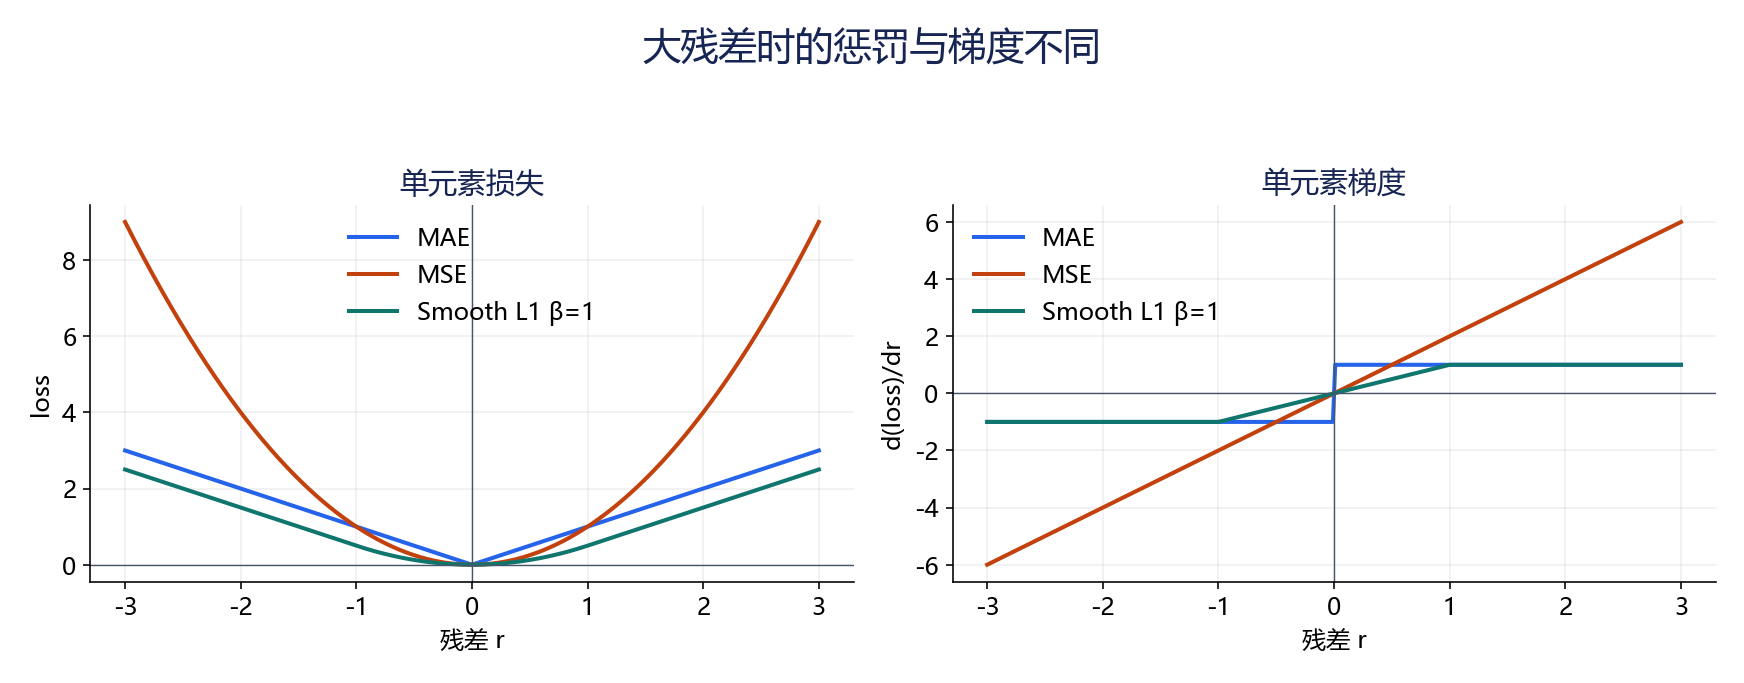

图中绘制单元素函数，尚未对batch或全部元素求均值：

- MAE：V形，远近误差的非零梯度幅度相同。
- MSE：二次曲线，大误差的惩罚和梯度增长更快。
- Smooth L1(β=1)：靠近0时二次，远离0时线性。

例子中同一个残差3，对应单元素MAE=3、MSE=9、Smooth L1=2.5。这些损失具有不同尺度，训练时的学习率也可能需要调整，不能随意换损失而默认训练行为完全一致。


## 18. reduction与shape：先明确平均的是哪些元素

常见 `reduction`：

| 设置 | 返回内容 | 使用方式 |
| --- | --- | --- |
| `"none"` | 每个元素或样本的损失 | 检查误差、按掩码汇总 |
| `"sum"` | 损失之和 | 需要总量时 |
| `"mean"` | 按接口规则取均值 | 默认常见训练目标 |

MSE/MAE/BCE通常对全部参与元素取平均。CrossEntropyLoss对整数类别标签计算每个样本的损失，再按其规则汇总；含类别权重和忽略项时平均分母有特殊规则。

```python
reduction_prediction = torch.tensor([[1.0, 3.0], [2.0, 4.0]])
reduction_target = torch.zeros_like(reduction_prediction)
element_losses = F.mse_loss(reduction_prediction, reduction_target, reduction="none")
assert element_losses.shape == (2, 2)
assert element_losses.sum().item() == 30.0
assert element_losses.mean().item() == 7.5
assert F.mse_loss(reduction_prediction, reduction_target, reduction="sum").item() == 30.0
assert F.mse_loss(reduction_prediction, reduction_target).item() == 7.5

ce_per_sample = F.cross_entropy(ce_logits.detach(), ce_targets, reduction="none")
assert ce_per_sample.shape == (2,)
assert torch.allclose(ce_per_sample.mean(), ce_value.detach())
```

若非标量损失要直接backward，需要提供上游梯度或先明确汇总成标量。损失张量的shape、预测与标签的shape都要检查，尤其回归中 `(N,1)` 对 `(N,)` 可能触发误广播。


## 19. 损失函数与输出层配套速查

| 任务 | 模型输出 | 标签 | 损失 |
| --- | --- | --- | --- |
| C类单标签分类 | `(N,C)` logits | `(N,)` long类别索引 | CrossEntropyLoss |
| 二分类，1个输出 | `(N,1)` logits | `(N,1)` 浮点0/1 | BCEWithLogitsLoss |
| 多标签，C个独立输出 | `(N,C)` logits | `(N,C)` 浮点标签 | BCEWithLogitsLoss |
| 回归 | 与目标相同shape的连续数值 | 同shape浮点值 | L1Loss/MSELoss/SmoothL1Loss等 |

交叉熵是可微训练目标，准确率是评价指标；MAE、MSE也可以用作评价指标，但必须说明定义、平均方式和单位。

以上分类接口是本篇使用的常见目标格式，CrossEntropyLoss也支持概率目标等其他模式，不能说所有场景都只能输入long标签。选择格式后要完整遵循该模式要求。


## 20. 梯度下降回顾：反向得到方向，更新迈出一步

$$\theta_{t+1}=\theta_t-\eta\nabla_\theta L.$$

梯度指向局部上升最快方向，减去梯度尝试降低损失；η为学习率。学习率过大可能越过低点甚至发散，过小则进展慢。

```python
descent_parameter = torch.tensor(0.0, requires_grad=True)
descent_before = (descent_parameter - 3.0).square()
descent_before.backward()
with torch.no_grad():
    descent_parameter -= 0.1 * descent_parameter.grad
descent_after = (descent_parameter - 3.0).square()
assert abs(descent_parameter.item() - 0.6) < 1e-6
assert descent_after.item() < descent_before.item()
print(descent_before.item(), "->", descent_after.item())
```

本篇模型用mini-batch梯度，因此损失不必每个batch或epoch严格单调下降。不同batch的损失也不能直接看成同一目标点连续变化。普通训练循环每次重建前向图、清理梯度，通常不需要 `retain_graph=True`。

全量、随机和小批量梯度下降的区别在于一次更新使用的数据量；SGD优化器也可用于全量或小批量更新，不因名字就必然每次只处理一个样本。


## 21. 反向传播：局部导数按链式法则传递

用一个单隐藏单元的网络说明：

$$z_1=w_1x+b_1,\quad a_1=\tanh(z_1),\quad
\hat y=w_2a_1+b_2,\quad L=(\hat y-y)^2.$$

令 `δ2=2(ŷ-y)`，则：

$$\frac{\partial L}{\partial w_2}=\delta_2a_1,\quad
\frac{\partial L}{\partial b_2}=\delta_2.$$

继续传到隐藏层：

$$\delta_1=\delta_2w_2(1-a_1^2),\quad
\frac{\partial L}{\partial w_1}=\delta_1x,\quad
\frac{\partial L}{\partial b_1}=\delta_1.$$

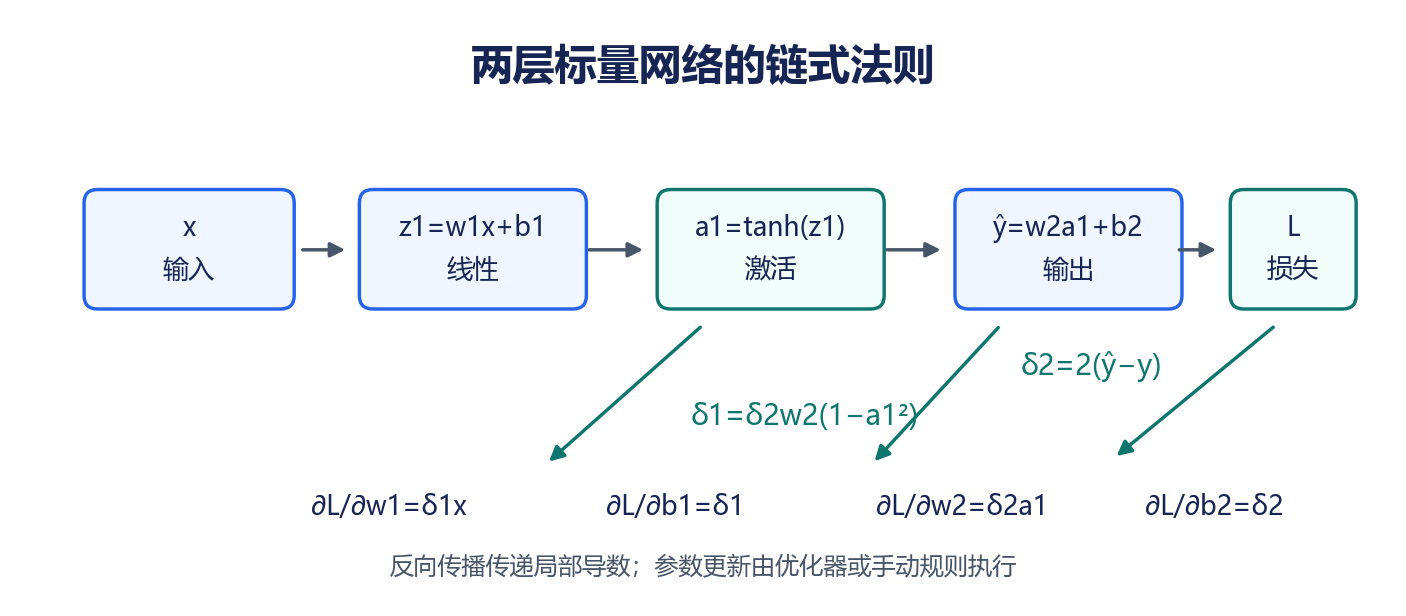

反向传播是高效计算梯度的算法，不是“反过来训练输入”，也不自动更新参数。复杂网络中有分支时，同一变量经过多条路径影响损失，各路径贡献需要相加。


### 21.1 手推梯度与PyTorch对照

使用x=2、y=1、w1=0.3、b1=0.1、w2=-0.4、b2=0.2，先前向，再反向。所有参数在同一次前向中取旧值，不要先更新输出层再用新权重手算隐藏层梯度。

```python
bp_x = torch.tensor(2.0, dtype=torch.float64)
bp_target = torch.tensor(1.0, dtype=torch.float64)
bp_w1 = torch.tensor(0.3, dtype=torch.float64, requires_grad=True)
bp_b1 = torch.tensor(0.1, dtype=torch.float64, requires_grad=True)
bp_w2 = torch.tensor(-0.4, dtype=torch.float64, requires_grad=True)
bp_b2 = torch.tensor(0.2, dtype=torch.float64, requires_grad=True)
bp_z1 = bp_w1 * bp_x + bp_b1
bp_a1 = torch.tanh(bp_z1)
bp_prediction = bp_w2 * bp_a1 + bp_b2
bp_loss = (bp_prediction - bp_target).square()
bp_loss.backward()

with torch.no_grad():
    delta2 = 2 * (bp_prediction - bp_target)
    delta1 = delta2 * bp_w2 * (1 - bp_a1.square())
    manual_bp_grads = [delta1 * bp_x, delta1, delta2 * bp_a1, delta2]
bp_parameters = [bp_w1, bp_b1, bp_w2, bp_b2]
for name, parameter, expected in zip(
        ["w1", "b1", "w2", "b2"], bp_parameters, manual_bp_grads):
    assert torch.allclose(parameter.grad, expected, atol=1e-12, rtol=0)
    print(name, parameter.grad.item())
```

本例没有batch平均，也没有额外1/2。若换成批次MSE或其他损失，需要把对应汇总与局部导数一起纳入，不能只复制最后一段公式。


## 22. 常见问题与排查

| 问题或误区 | 原因与处理 |
| --- | --- |
| 每轮loss差不多，隐藏单元都相同 | 检查初始化对称性、梯度与参数是否改变 |
| 偏置初始化为0就无法训练 | 需要区分偏置与隐藏权重；许多偏置可用0 |
| 默认Linear没有初始化 | 框架有默认初始化，手动设置是选择不同策略 |
| 自定义参数找不到 | 检查Module属性、Parameter、ModuleList注册 |
| 每次forward临时创建层 | 参数反复新建，改为在init中创建 |
| train()后模型会自动训练 | 只切换模式，仍需完整训练循环 |
| eval()后不再构建梯度图 | eval不等于no_grad，两者可同时使用 |
| loss.backward()后参数没变化 | 还需要optimizer.step或手动更新 |
| 先Softmax再CrossEntropyLoss | 直接输入logits，避免目标被改变 |
| BCE标签是long或shape不一致 | 使用同shape浮点标签 |
| 换了sum，梯度突然变大 | 汇总改变了尺度，检查元素数和学习率 |
| Smooth L1直接等同Huber | β≠1时有缩放关系，明确阈值与实现 |
| 回归loss能算，但出现N×N残差 | 预测和标签shape发生误广播 |
| batch均值简单平均 | 不同batch大小时应按样本数或有效元素数加权 |
| 每个batch loss必须下降 | 小批量目标不同，不能要求逐步单调 |
| 手算隐藏梯度时用了更新后权重 | 所有梯度先在同一旧参数状态计算，再统一更新 |

排查顺序：检查数据与标签格式→打印logits/target shape→确认损失输入含义→查看参数注册和grad→确认清梯度与更新→再考虑学习率、初始化与模型复杂度。


## 23. 练习与参考答案

1. 全连接网络4→8→3，两个层均有偏置，多少参数？  
   **答：**`4×8+8+8×3+3=67`。
2. `nn.Linear(4,8)` 权重shape与fan_in分别是什么？  
   **答：**`(8,4)` 与4。
3. logits形状 `(16,5)`，使用整数标签的CrossEntropyLoss，标签格式？  
   **答：**`(16,)` long，类别编号0—4，不先Softmax。
4. 预测 `[-2,0,3]`、目标为0，MAE和MSE分别是多少？  
   **答：**5/3与13/3，对全部3个元素取均值。
5. Smooth L1的β=1，残差0.5与2的单元素损失分别是多少？  
   **答：**0.125与1.5。
6. batch_size=24、样本数145、drop_last=False，一个epoch多少批？  
   **答：**7批，最后1个样本，不是每批都24。
7. backward与step的区别？  
   **答：**前者计算并累积梯度，后者按优化规则更新参数。

```python
exercise_network = nn.Sequential(nn.Linear(4, 8), nn.ReLU(), nn.Linear(8, 3))
assert sum(p.numel() for p in exercise_network.parameters()) == 67
assert exercise_network[0].weight.shape == (8, 4)
exercise_residual = torch.tensor([0.5, 2.0])
exercise_smooth = F.smooth_l1_loss(exercise_residual, torch.zeros_like(exercise_residual),
                                  beta=1.0, reduction="none")
assert torch.allclose(exercise_smooth, torch.tensor([0.125, 1.5]))
exercise_loader = DataLoader(TensorDataset(torch.arange(145)), batch_size=24)
assert len(exercise_loader) == 7
assert [len(batch[0]) for batch in exercise_loader][-1] == 1
print("参数数量、损失数值和最后一个batch已核对")
```


## 24. day04目录与来源范围

| 编号 | 已核对的视频主题 | 对应笔记 |
| --- | --- | --- |
| 01 | 参数初始化_介绍 | 第2、4—5节 |
| 02 | 参数初始化_代码演示 | 第3—6节 |
| 03 | 神经网络_搭建流程介绍 | 第6—9节 |
| 04 | 神经网络_搭建代码实现 | 第6—8节 |
| 05 | 神经网络_模型训练 | 第9—11节 |
| 06 | 神经网络_总结 | 第19、22—23节 |
| 07 | 损失函数_多分类交叉熵损失介绍 | 第12节 |
| 08 | 损失函数_二分类交叉熵损失介绍 | 第13节 |
| 09 | 损失函数_MAE损失函数介绍 | 第14节 |
| 10 | 损失函数_MSE损失函数介绍 | 第15节 |
| 11 | 损失函数_Smooth L1损失函数介绍 | 第16—18节 |
| 12 | 梯度下降算法回顾 | 第20节 |
| 13 | 反向传播(了解) | 第21节 |

本篇来源范围为视频文件名核对，未读取教师压缩包正文，未逐段转录视频。人工三分类数据、训练测试划分、初始化方案、损失数值和两层标量反向传播例子均为独立教学示例或补充，不声称与视频具体代码和数值相同。

延伸查阅：[参数初始化](https://docs.pytorch.org/docs/stable/nn.init.html)、[Module](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html)、[CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)、[BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html)、[SmoothL1Loss](https://docs.pytorch.org/docs/stable/generated/torch.nn.SmoothL1Loss.html)。本篇所述API行为以实际CPU运行核对，链接供进一步查阅。

图全部为本文自绘并作为Notebook附件存储，不依赖单独图片文件。下一篇按day05继续：优化器、学习率调整、Dropout、BatchNorm与分类案例数据准备。

本次验证环境：Python 3.13.7、PyTorch 2.14.1+cpu、CPU。顺序执行 21 段Python代码通过，5张图均内嵌为附件；参数初始化、数据划分、DataLoader批次、三分类训练、各损失函数梯度与反向传播示例均已核对。训练图数值与示例实际运行一致，未在GPU上验证。
